# Домашняя работа 6.

In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb

## Предисловие.
- Применение модели.
- Анализ доступных данных.
- Определение целевой переменной.
- Определение метрик качества модели.

Мы знаем, что начальными этапами построения ML-модели являются определение способа приенение модели, анализ доступных данных и определение целевой переменной. Однако в этой домашке мы не задаёмся этими вопросами, так как нам сразу подсказали и применение модели для максимизации прибыли, и целевую переменную, и даже данные предоставили, и указали цену ошибок разного рода: за ошибку первого рода мы просто не получим никакой прибыли, но и потерь никаких не понесём; за ошибку второго рода мы получаем штраф, равный 0.75 * desired_credit_limit. За правильный прогноз мы получим прибыль = desired_credit_limit * 0.18. 

Так как у нас есть целевая переменная - default_within_1y, то на этом же этапе мы будем определять метрики качества модели. Для этой задачи у нас двоякая ситуация: с одной стороны, если мы допустим ошибку второго рода, то мы получим ощутимый штраф, с другой стороны, если мы допускаем ошибку первого рода, то мы просто не получаем денег, причём заметим, что коэффициент у второй ошибки куда больше, чем у прибыли, поэтому при равенстве кредитного лимита нам куда важнее минимизировать ошибку второго рода. Мы можем пойти по двум сценариям: минимизировать штрафы, использую метрику качества Recall, так как нам важно отловить все дефолты, либо максимизировать выгоду. А можно попробовать совместить в себе два подхода, используя свою метрику:

$$
Q(a, X, y) = \sum_{i=1}^n [\mathbb{I}(a(x^{(i)}) = y_i = 1) * 0 + \mathbb{I}(a(x^{(i)}) =1, y_i = 0) * 0 + \mathbb{I}(a(x^{(i)}) = 0, y_i = 1) (-0.75 * x^{(i)} _{\text{dcl}}) + \mathbb{I}(a(x^{(i)}) = 0, y_i = 0) (0.18 * x^{(i)} _{\text{dcl}})] =
$$

$$
=  \sum_{i=1}^n [\mathbb{I}(a(x^{(i)}) = 0, y_i = 1) (-0.75 * x^{(i)} _{\text{dcl}}) + \mathbb{I}(a(x^{(i)}) = 0, y_i = 0) (0.18 * x^{(i)} _{\text{dcl}})] \to max_a
$$
Где a - наша модель, X - наши данные, y - истинные метки.

Таким образом, мы будем оценивать нашу модель по абсолютной чистой прибыли.

Минутка занимательной, но не очень применительной математики, которая пришла мне в голову: <details> ecли максимизировать не такой функционал, а поделить его ещё на n, то мы получим эмпирическое среднее. А тогда, если n достаточно большой, то мы можем сказать, что мы максимизируем такое матожидание: 
$\mathbb{E}[\mathbb{I}(a(\xi) = 0, \eta = 1) (-0.75 * \xi _{\text{dcl}}) + \mathbb{I}(a(\xi) = 0, \eta = 0) (0.18 * \xi _{\text{dcl}})]$, а если ещё и если потребовать независимости $\xi _{\text{dcl}}$ и $\eta$, которые, кстати, случайные величины, и независимость $\xi _{\text{dcl}}$ от других переменных, то вся наша метрика схлопнется в эмпирическую оценку: $Q(a, X, y) = \overline x_{dcl}(0.18\frac{TN}{n} - 0.75 \frac{FN}{n})$, что круто с точки зрения простоты и наглядности, но для корректности мы сделали слишком сильное допущение о независимости, да и абсолютные значения в нашем случае предпочтительнее относительных, потому что нам интересна абсолютная прибыль. </details>

In [2]:
def income_metric(y_true, y_pred, x_dcl, threshold):
    x_dcl = np.asarray(x_dcl)

    # На этапе с подбором 
    # гиперпараметров есть
    # объяснение, почему здесь
    # написан какой-то порог и
    # откуда он берётся.

    y_pred = y_pred >= threshold
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    res = 0 

    res += np.sum(x_dcl[(y_pred == 0) & (y_true == 0) ]) * 0.18
    res -= np.sum(x_dcl[(y_pred == 0) & (y_true == 1) ]) * 0.75

    return res

## EDA.
- Пропуски.
- Распределения, выбросы, аномалии и стабильность данных во времени.
- Корреляции и другие зависимости в данных и с таргетом.

### Общая информация и пропуски.

In [3]:
df = pd.read_csv('dz-system-design.csv')
df = df.drop(columns = ['client_id'])
df.head()

,age,income,education,gender,employment_status,years_employed,marital_status,num_dependents,home_ownership,credit_history_length,num_credit_lines,num_past_defaults,dti_ratio,credit_utilization,existing_loan_amount,credit_score,region,desired_credit_limit,default_within_1y
0,21.0,27104.33,NaN,Female,Retired,28.8,Married,0,Mortgage,14.9,2,2,NaN,0.703,34983.41,566.0,Urban,11489.47,1
1,44.0,16862.17,NaN,Male,Self-Employed,2.2,Married,1,Mortgage,11.8,1,1,0.039,0.467,17232.52,599.0,Rural,18024.43,0
2,29.0,42902.03,NaN,Female,Employed,9.9,Married,2,Rent,3.4,2,0,0.340,0.074,21534.80,704.0,Suburban,50290.26,0
3,40.0,33427.68,Bachelor,Male,NaN,0.9,Divorced,1,Own,15.3,4,2,0.047,0.555,5413.00,554.0,Rural,32839.29,1
4,NaN,12398.00,Bachelor,Female,Employed,3.8,Married,0,Mortgage,21.0,2,1,0.458,0.112,818.34,741.0,Rural,5899.81,0


Есть хорошие новости и плохие. Во-первых, стабильность фичей во времени проверять не нужно (а вместе с ней тренды, сезонности и всё, что связано со временем) - временной зависимости здесь просто нет. Во-вторых, пропуски в данных всё же есть, а значит, нам нужно будет с ними работать.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 19 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   age                    995273 non-null   float64
 1   income                 995230 non-null   float64
 2   education              945771 non-null   object 
 3   gender                 1000000 non-null  object 
 4   employment_status      995169 non-null   object 
 5   years_employed         1000000 non-null  float64
 6   marital_status         1000000 non-null  object 
 7   num_dependents         1000000 non-null  int64  
 8   home_ownership         1000000 non-null  object 
 9   credit_history_length  995219 non-null   float64
 10  num_credit_lines       1000000 non-null  int64  
 11  num_past_defaults      1000000 non-null  int64  
 12  dti_ratio              995223 non-null   float64
 13  credit_utilization     1000000 non-null  float64
 14  existing_loan_amoun

Итак, мы видим, что наши категориальный фичи имеет тип данных ```object```, но для корректной работы моделей нужно будет их закодировать либо ограничиться переводом в ```category```, чтобы закинуть их в бустинг.

In [5]:
for x in df.select_dtypes(include=['object']):
    df[x] = df[x].astype('category')

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 19 columns):
 #   Column                 Non-Null Count    Dtype   
---  ------                 --------------    -----   
 0   age                    995273 non-null   float64 
 1   income                 995230 non-null   float64 
 2   education              945771 non-null   category
 3   gender                 1000000 non-null  category
 4   employment_status      995169 non-null   category
 5   years_employed         1000000 non-null  float64 
 6   marital_status         1000000 non-null  category
 7   num_dependents         1000000 non-null  int64   
 8   home_ownership         1000000 non-null  category
 9   credit_history_length  995219 non-null   float64 
 10  num_credit_lines       1000000 non-null  int64   
 11  num_past_defaults      1000000 non-null  int64   
 12  dti_ratio              995223 non-null   float64 
 13  credit_utilization     1000000 non-null  float64 
 14  exi

In [6]:
df.describe()

,age,income,years_employed,num_dependents,credit_history_length,num_credit_lines,num_past_defaults,dti_ratio,credit_utilization,existing_loan_amount,credit_score,desired_credit_limit,default_within_1y
count,995273.000000,9.952300e+05,1000000.000000,1000000.000000,995219.000000,1000000.000000,1000000.000000,995223.000000,1000000.000000,1.000000e+06,995193.000000,1000000.000000,1000000.000000
mean,41.514878,1.427896e+05,4.999215,1.201603,11.852056,4.019079,0.400036,0.387436,0.390784,1.310388e+05,629.015518,28798.842963,0.359834
std,37.952941,1.186293e+06,4.987925,1.095976,6.352123,11.885286,0.632778,1.189330,0.235669,1.135642e+06,73.717969,20424.954977,0.479952
min,-5.000000,-4.997952e+04,0.000000,0.000000,-29.988243,0.000000,0.000000,0.000000,-1.999783,-1.999733e+04,-100.000000,971.320000,0.000000
25%,32.000000,2.583063e+04,1.400000,0.000000,7.600000,2.000000,0.000000,0.162000,0.241000,1.191231e+04,599.000000,14411.882500,0.000000
50%,40.000000,3.638822e+04,3.500000,1.000000,11.000000,3.000000,0.000000,0.266000,0.384000,2.483981e+04,632.000000,23724.240000,0.000000
75%,48.000000,5.127900e+04,6.900000,2.000000,15.300000,4.000000,1.000000,0.393000,0.542000,4.289910e+04,662.000000,37435.732500,1.000000
max,999.000000,2.029259e+07,40.000000,8.000000,50.000000,199.000000,6.000000,19.998379,0.995000,1.761798e+07,1500.000000,461088.310000,1.000000


### Распределения и всё с этим связанное.

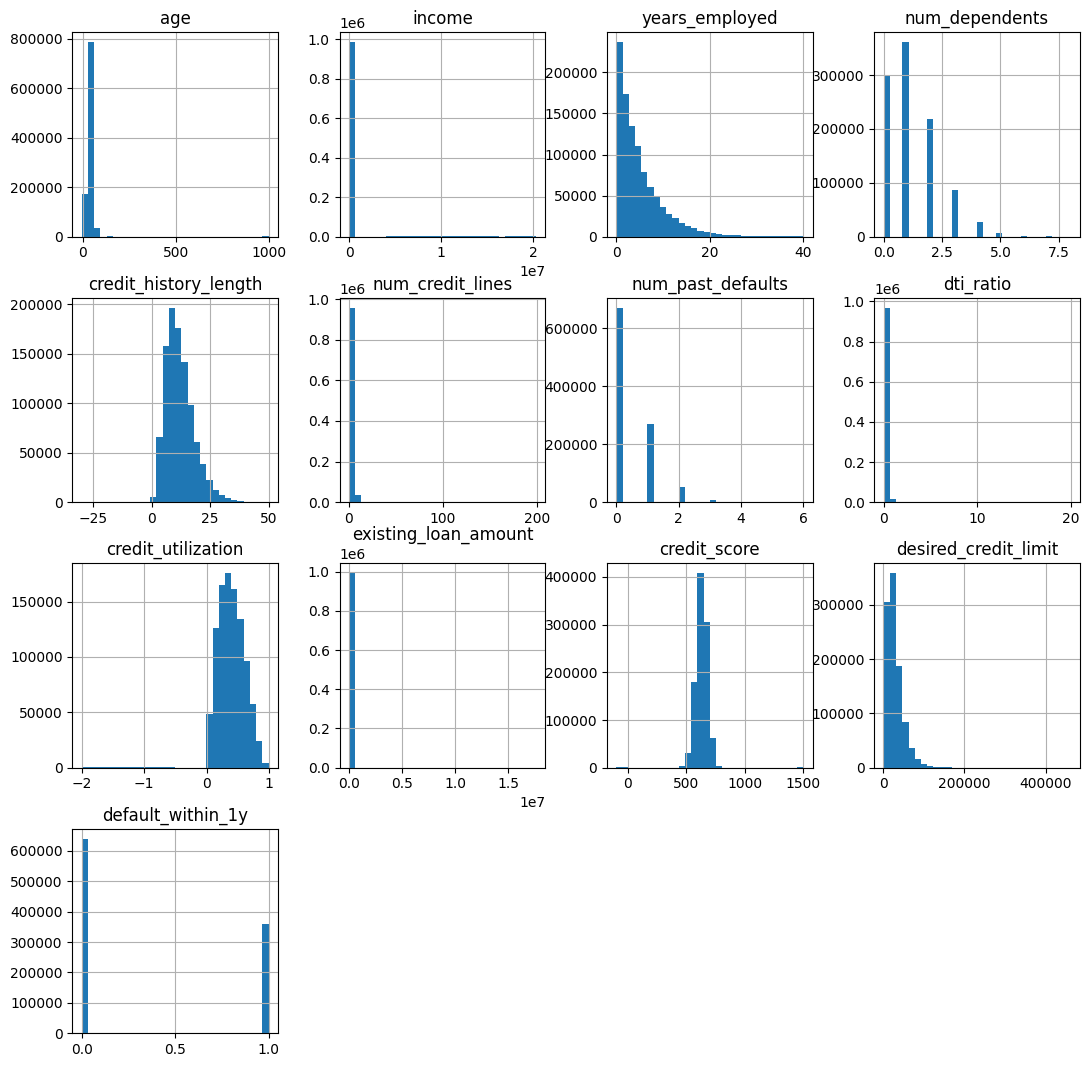

In [7]:
df.hist(figsize=(13, 13), bins = 30)

plt.show()

В некоторых данных уже отсюда видны выбросы и аномалии: 
- ```age```. Кому-то там уже под тыщу лет, такие едва ли нам отдадут кредит :).
- ```income``` весь сосредоточен в одном бине, при этом есть несколько маленьких бинов, которые находятся правее основного.
- ```credit_history_length```. Отрицательная кредитная история?
- ```num_credit_lines```. Видимо есть какие-то редкие большие значения.
- ```dti_ratio```. Аналогично прошлому пункту.
- ```credit_utilization```. -2 - странное значение для утилизации.
- ```credit_score```. Основная масса наблюдений сосредоточена в одном месте, но слева и справа есть маловероятные сильно отличающиеся значения.

Визуально фичи имеют следующее распределение:
- ```years_employed```, ```desired_credit_limit``` имеют явное экспоненциальное распределение.
- ```num_dependents```, ```num_past_defaults``` оба похожи на дискретное экспоненциальное распределение, то есть на распределение Пуассона.
- ```credit_score``` похож на сильно знакомый колокол Гаусса, только сдвинутый на ~600 вправо, то есть это нормальное распределение.
- ```credit_utilization``` сосредоточен в отрезке $[0, 1]$, если выкинуть аномалии/выбросы, то это похоже на Бета-распределение.
- ```credit_history_length``` без выбросов похоже на логнормальное распределение по своему носителю и длинному хвосту.
- У остальных визуально невозможно определить распределение из-за выбросов.

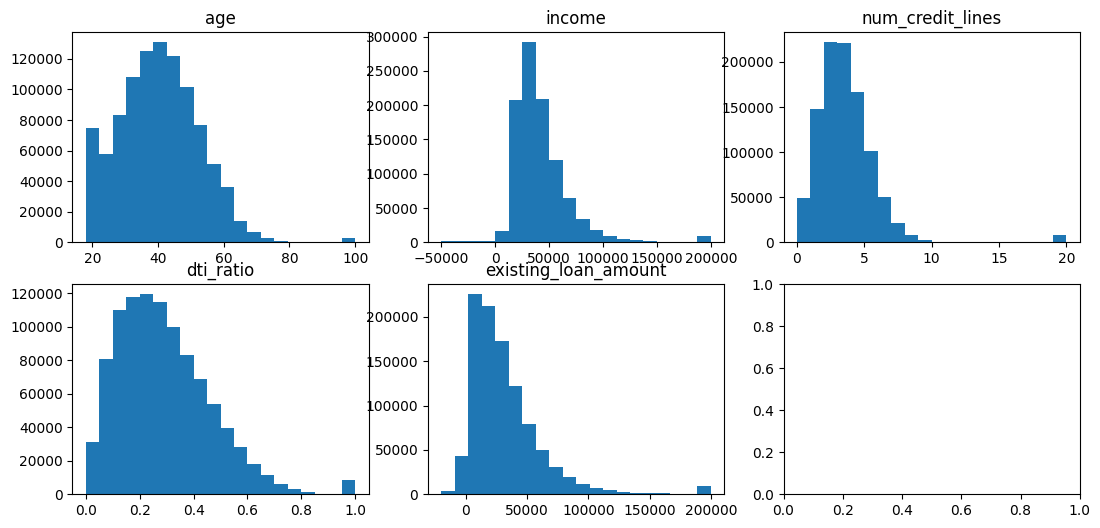

In [8]:
fig, axes = plt.subplots(2, 3, figsize = (13, 6))
axes[0][0].hist(df['age'].clip(upper=100, lower = 18), bins = 20)
axes[0][0].set_title('age')

axes[0][1].hist(df['income'].clip(upper=200_000), bins = 20)
axes[0][1].set_title('income')


axes[0][2].hist(df['num_credit_lines'].clip(upper=20), bins = 20)
axes[0][2].set_title('num_credit_lines')

axes[1][0].hist(df['dti_ratio'].clip(upper=1), bins = 20)
axes[1][0].set_title('dti_ratio')

axes[1][1].hist(df['existing_loan_amount'].clip(upper=2e5), bins = 20)
axes[1][1].set_title('existing_loan_amount')
plt.show()

Здесь мы видим, что если не смотреть на выбросы/аномалии, то у большинства (```income```, ```num_credit_lines```, ```dti_ratio```, ```existing_loan_amount```) будет что-то около логнормального распределения, это и объясняет такие тяжелые хвосты у них, но у ```age``` распределение больше похоже на отсеченное слева нормальное распределение. Теперь посмотрим на категориальные признаки.

In [9]:
for x in df.select_dtypes(include=['category']):
    print(f'{df[x].value_counts(normalize=True)}\n')

education
Bachelor      0.368578
HighSchool    0.368570
Master        0.210051
PhD           0.052801
Name: proportion, dtype: float64

gender
Male      0.500269
Female    0.499731
Name: proportion, dtype: float64

employment_status
Employed         0.600054
Self-Employed    0.200239
Unemployed       0.099893
Retired          0.099814
Name: proportion, dtype: float64

marital_status
Married     0.450461
Single      0.349856
Divorced    0.149954
Widowed     0.049729
Name: proportion, dtype: float64

home_ownership
Mortgage    0.400924
Own         0.300049
Rent        0.299027
Name: proportion, dtype: float64

region
Urban       0.501199
Suburban    0.300409
Rural       0.198392
Name: proportion, dtype: float64



Местами в категориальных признаках есть дизбаланс, но, например, для бустинга такой дизбаланс (самый сильный - в 9 раз, 45 процентов против 5) не считается чем-то серьёзным.

### Корреляция и связи.

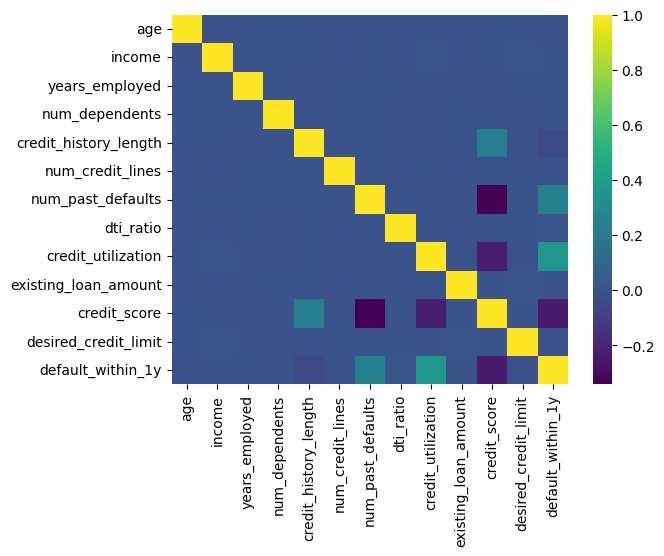

In [10]:
sns.heatmap(df.select_dtypes(include=['float64', 'int64']).corr(), cmap='viridis')

plt.show()

Как мы видим, здесь ничего криминального нет, так как сильно коррелирующих признаков в наших данных нет.

## Разделение данных на подвыборки.

Нам важна стратификация, так как у самого таргета есть дизбаланс, который нам нужно учесть.

In [11]:
from sklearn.model_selection import train_test_split

target = df['default_within_1y']
data = df.drop(columns=['default_within_1y'])

X_trainval, X_test, y_trainval, y_test = train_test_split(data, target, train_size=0.8, stratify=target, random_state=52)
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, train_size=7/8, stratify=y_trainval, random_state=52)

## Подбор модели и отбор переменных.
- Выбор модели на основе информации с EDA.
- Выбор подходящих переменных.
- Обработка переменных (кодировка, линеаризация, ...)

Во время анализа данных у нас накопилось довольно много предпосылок:
- Тяжелые хвосты у большинства распределений.
- Ощутимое количество выбросов и аномалий в данных.
- Пропуски в данных.
- Большое количество категориальных фичей.
- Разные масштабы данных.

Поэтому для борьбы со всеми этими ограничениями мы выбираем бустинг: во-первых, он построен на деревьях с предикатами вида $\{x \ge t\}$, они одновременно решают как проблему больших хвостов, так и выбросов с аномалиями и разного масштаба, так как такие предикаты успешно их обрабатывают, во-вторых, он из коробки хорошо работает что с категориальными фичами, что с пропусками, поэтому в нашем случае это идеальный выбор. Кажется, что у нас не так много переменных, причём они не являются сильно коррелирующими, но всё же посмотрим, можем ли мы выкинуть какие-то переменные, не потеряв в качестве и ускорив работу модели, для чего произведём отбор переменных по shap-values, так как первичный фильтрующий отбор по корреляции не привёл к выбрасыванию переменных.

In [12]:
model = lgb.LGBMClassifier(n_estimators=500, learning_rate=1e-3, min_child_samples=50, random_state=52)

model = model.fit(X_train, y_train, eval_X =X_val, eval_y = y_val, callbacks=[lgb.early_stopping(stopping_rounds=10)])


[LightGBM] [Info] Number of positive: 251884, number of negative: 448116
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.044046 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2303
[LightGBM] [Info] Number of data points in the train set: 700000, number of used features: 18
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.359834 -> initscore=-0.576083
[LightGBM] [Info] Start training from score -0.576083
Training until validation scores don't improve for 10 rounds
Did not meet early stopping. Best iteration is:
[500]	valid_0's binary_logloss: 0.55939


In [13]:
import shap
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_val)

c:\Users\temy2\AppData\Local\Programs\Python\Python310\lib\site-packages\shap\explainers\_tree.py:586: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


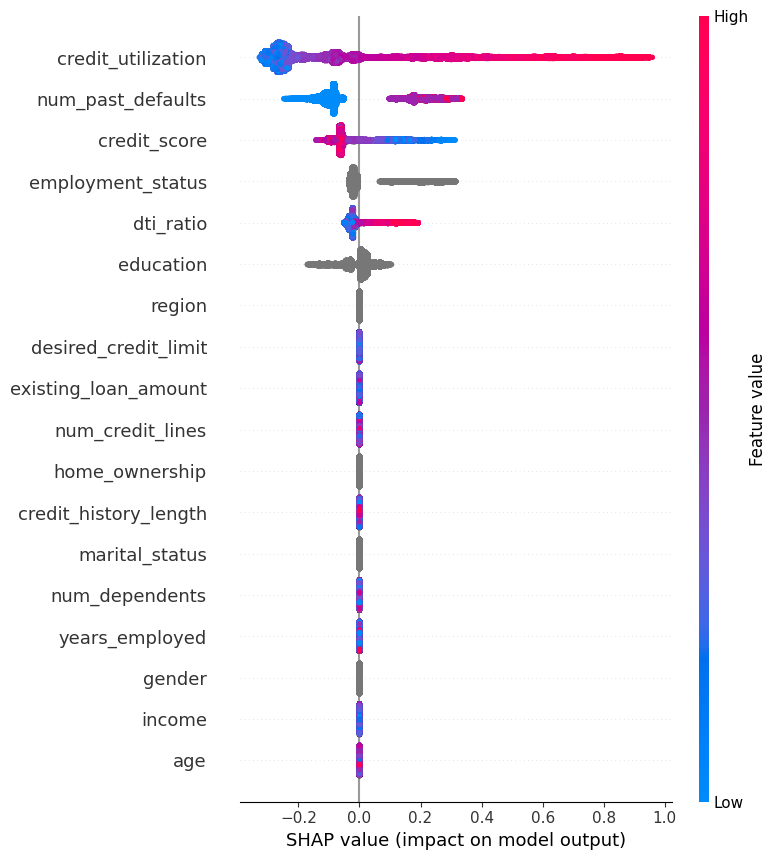

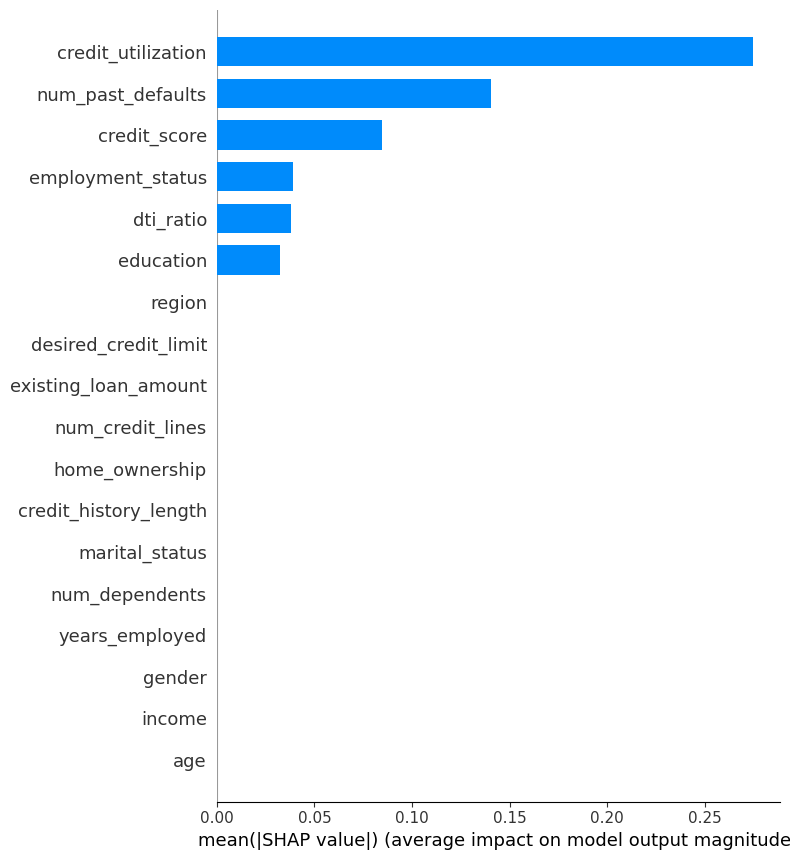

In [14]:
cols = [f for f in df.columns if f != 'default_within_1y']
shap.summary_plot(shap_values, X_val, feature_names=cols, show = True)

shap.summary_plot(shap_values, X_val, feature_names=cols, show = True, plot_type='bar')

Вот это забавное наблюдение, что по шапам полезными оказались только 6 признаков из 18, хотя по некоторыми фичам было сразу примерно понятно, что они мусорные, особенно возраст. Однако мы не спешим вышвыривать 2/3 переменных, сначала посмотрим их важность по gain.

In [15]:
gain_importance = model.booster_.feature_importance(importance_type='gain')
for x, imp in zip(cols, gain_importance):
    print(f"Feature: {x} | its importance: {imp}")

Feature: age | its importance: 0.0
Feature: income | its importance: 0.0
Feature: education | its importance: 2234239.9166259766
Feature: gender | its importance: 0.0
Feature: employment_status | its importance: 2387335.4981384277
Feature: years_employed | its importance: 0.0
Feature: marital_status | its importance: 0.0
Feature: num_dependents | its importance: 0.0
Feature: home_ownership | its importance: 0.0
Feature: credit_history_length | its importance: 0.0
Feature: num_credit_lines | its importance: 0.0
Feature: num_past_defaults | its importance: 9608119.630432129
Feature: dti_ratio | its importance: 2041335.5335998535
Feature: credit_utilization | its importance: 41937786.13961792
Feature: existing_loan_amount | its importance: 0.0
Feature: credit_score | its importance: 7640199.325500488
Feature: region | its importance: 0.0
Feature: desired_credit_limit | its importance: 0.0


Выводы по шапам подтвердились: у 12 из 18 фичей важность нулевая, поэтому их все можно выбросить безопасно из модели: станет только лучше.

In [16]:
inf_cols = [cols[i] for i in np.argsort(gain_importance)[-6:]]

inf_cols, len(inf_cols)

(['dti_ratio',
  'education',
  'employment_status',
  'credit_score',
  'num_past_defaults',
  'credit_utilization'],
 6)

Так как нам не нужно никак обрабатывать дальше наши переменные из-за того, что мы используем бустинг, то переходим дальше.

In [17]:
target = df['default_within_1y']
data = df[inf_cols]

X_trainval, X_test, y_trainval, y_test = train_test_split(data, target, train_size=0.8, stratify=target, random_state = 52)
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, train_size=7/8, stratify=y_trainval, random_state = 52)
X_train

,dti_ratio,education,employment_status,credit_score,num_past_defaults,credit_utilization
207949,0.265,HighSchool,Unemployed,723.0,0,0.258
201451,0.103,NaN,Employed,686.0,0,0.378
216905,0.184,HighSchool,Self-Employed,631.0,0,0.655
553010,0.207,HighSchool,Unemployed,584.0,1,0.163
201732,0.532,HighSchool,Retired,633.0,1,0.208
...,...,...,...,...,...,...
151284,0.182,HighSchool,Employed,581.0,1,0.427
400412,0.151,Bachelor,Employed,663.0,0,0.787
84863,0.394,HighSchool,Employed,711.0,0,0.277
373173,0.331,PhD,Employed,582.0,0,0.435


## Гиперпараметры.

Кроме всех базовых гиперпараметров, мы ещё будем подбирать threshold для вероятности дефолта, так как стандартные 0.5 - это слишком много для нашей модели. На самом деле, из-за того, что мы сильно штрафуемся из-за ошибки 2 рода, вероятность дефолта равная даже 1/3 для нас уже очень большой риск, который мы не готовы взять из-за больших убытков, поэтому мы поставим метку дефолта и кредит не выдадим. Как нам неоднократно говорили на лекциях, все пороги, исходя из которых принимаются решения, должны быть продиктованы бизнесовым смыслом, здесь же мы позволяем себе не считать вручную допустимую вероятность, с которой мы готовы выдавать кредиты, чтобы заработать, а оставить это на откуп отпуне.

In [18]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

x_dcl_val = df['desired_credit_limit'][y_val.index]

def objective(trial):
    params = {
        'objective': 'binary',
        'metric': 'auc',
        'verbosity': -1,
        'boosting_type': 'gbdt',
        'random_state': 52,
        'n_estimators' : trial.suggest_int('n_estimators', 100, 1000),
        'num_leaves': trial.suggest_int('nl', 10, 200),   
        'learning_rate': trial.suggest_float('lr', 0.0001, 0.3, log = True), 
        'feature_fraction': trial.suggest_float('ff', 0.5, 1, step=0.1), 
    }

    model = lgb.LGBMClassifier(**params)
    model = model.fit(X_train, y_train, eval_X = X_val, eval_y = y_val, callbacks=[lgb.early_stopping(stopping_rounds=10)])

    threshold = trial.suggest_float('threshold', 0.01, 0.9)
    pred = model.predict_proba(X_val)[:, 1]
    
    return income_metric(y_val, pred, x_dcl_val, threshold)
    

sampler = optuna.samplers.TPESampler(seed=52)
study = optuna.create_study(direction = 'maximize', sampler=sampler)
study.optimize(objective, n_trials=50)

print("Best params:", study.best_params)
print("Best income:", study.best_value)

Training until validation scores don't improve for 10 rounds
Early stopping, best iteration is:
[10]	valid_0's auc: 0.807684
Training until validation scores don't improve for 10 rounds
Early stopping, best iteration is:
[76]	valid_0's auc: 0.834174
Training until validation scores don't improve for 10 rounds
Early stopping, best iteration is:
[137]	valid_0's auc: 0.834529
Training until validation scores don't improve for 10 rounds
Early stopping, best iteration is:
[10]	valid_0's auc: 0.831994
Training until validation scores don't improve for 10 rounds
Early stopping, best iteration is:
[10]	valid_0's auc: 0.822755
Training until validation scores don't improve for 10 rounds
Early stopping, best iteration is:
[122]	valid_0's auc: 0.834769
Training until validation scores don't improve for 10 rounds
Early stopping, best iteration is:
[12]	valid_0's auc: 0.828118
Training until validation scores don't improve for 10 rounds
Did not meet early stopping. Best iteration is:
[539]	valid_0'

## Измерение качества модели.

In [19]:
best_params = study.best_params
best_params.update(
    {'objective' : 'binary',
    'metric': 'auc',
    'verbosity': -1,
    'boosting_type': 'gbdt',
    'random_state': 52,
    }
)
model = lgb.LGBMClassifier(**best_params)

model = model.fit(X_train, y_train)


In [20]:
x_dcl_test = df['desired_credit_limit'][y_test.index]
income_metric(y_test, model.predict_proba(X_test)[:, 1], x_dcl_test, best_params['threshold'])

np.float64(178785976.0511999)

## La Finale!

In [21]:
final_df = pd.read_csv('OOT.csv')

for x in final_df.select_dtypes(include = ['object']):
    final_df[x] = final_df[x].astype('category')

final_pred = model.predict_proba(final_df[inf_cols])[:, 1]
final_pred = (final_pred >= best_params['threshold']).astype(int)

final_df['flag'] = final_pred

print(income_metric(final_df['default_within_1y'], final_df['flag'], final_df['desired_credit_limit'], best_params['threshold']))
final_df

892804950.8924999


,client_id,age,income,education,gender,employment_status,years_employed,marital_status,num_dependents,home_ownership,...,num_credit_lines,num_past_defaults,dti_ratio,credit_utilization,existing_loan_amount,credit_score,region,desired_credit_limit,default_within_1y,flag
0,987232,21.0,27104.33,NaN,Female,Retired,28.8,Married,0,Mortgage,...,2,2,NaN,0.703,34983.41,566.0,Urban,11489.47,1,1
1,79955,44.0,16862.17,NaN,Male,Self-Employed,2.2,Married,1,Mortgage,...,1,1,0.039,0.467,17232.52,599.0,Rural,18024.43,0,1
2,567131,29.0,42902.03,NaN,Female,Employed,9.9,Married,2,Rent,...,2,0,0.340,0.074,21534.80,704.0,Suburban,50290.26,0,0
3,500892,40.0,33427.68,Bachelor,Male,NaN,0.9,Divorced,1,Own,...,4,2,0.047,0.555,5413.00,554.0,Rural,32839.29,1,1
4,55400,NaN,12398.00,Bachelor,Female,Employed,3.8,Married,0,Mortgage,...,2,1,0.458,0.112,818.34,741.0,Rural,5899.81,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
999995,259179,28.0,67774.19,HighSchool,Female,Employed,1.0,Married,0,Own,...,1,1,0.788,0.100,10892.98,601.0,Suburban,45758.36,1,1
999996,365839,32.0,17025.75,Bachelor,Male,Self-Employed,14.6,Single,0,Own,...,10,0,0.456,0.185,12944.98,635.0,Urban,7076.32,1,0
999997,131933,34.0,71966.17,NaN,Male,Employed,11.4,Married,1,Rent,...,4,0,0.324,0.470,62309.72,674.0,Urban,16688.02,0,1
999998,671156,36.0,45034.93,Bachelor,Female,Employed,2.5,Married,0,Mortgage,...,3,0,0.315,0.379,7084.83,626.0,Suburban,26508.98,0,0


In [22]:
final_df.to_csv("OOT_Bartia.csv", index=False)